# EfficientNetB0 and MobileNetV2 Baseline Comparison

This notebook trains and evaluates EfficientNetB0 and MobileNetV2 for five-class liver fibrosis ultrasound image classification (F0–F4).

##Install and import dependencies

In [1]:
import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import kagglehub

from sklearn.model_selection import train_test_split
from sklearn.utils import shuffle
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_auc_score
)
from sklearn.preprocessing import label_binarize
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB0, MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


##Download the dataset

In [2]:
path = kagglehub.dataset_download(
    "vibhingupta028/liver-histopathology-fibrosis-ultrasound-images"
)
dataset_path = os.path.join(path, "Dataset", "Dataset")
print("Dataset path:", dataset_path)
print("Class folders found:", os.listdir(dataset_path))

Using Colab cache for faster access to the 'liver-histopathology-fibrosis-ultrasound-images' dataset.
Dataset path: /kaggle/input/liver-histopathology-fibrosis-ultrasound-images/Dataset/Dataset
Class folders found: ['F0', 'F1', 'F4', 'F3', 'F2']


##Load images and labels

In [3]:
CLASS_NAMES = ["F0", "F1", "F2", "F3", "F4"]
CLASS_TO_LABEL = {name: idx for idx, name in enumerate(CLASS_NAMES)}
IMG_SIZE = (128, 128)
NUM_CLASSES = len(CLASS_NAMES)

img_data_list = []
labels = []
image_paths = []

for class_name in CLASS_NAMES:
    class_dir = os.path.join(dataset_path, class_name)
    if not os.path.isdir(class_dir):
        raise FileNotFoundError(f"Missing class folder: {class_dir}")

    valid_count = 0
    for filename in sorted(os.listdir(class_dir)):
        img_path = os.path.join(class_dir, filename)
        image = tf.keras.utils.load_img(img_path, target_size=IMG_SIZE)
        image_array = tf.keras.utils.img_to_array(image)  # RGB, float pixel values 0–255
        img_data_list.append(image_array)
        labels.append(CLASS_TO_LABEL[class_name])
        image_paths.append(img_path)
        valid_count += 1

    print(f"{class_name}: loaded {valid_count} images")

# Keep the requested normalization exactly as specified.
data = np.array(img_data_list, dtype="float32") / 255.0
labels = np.array(labels, dtype=np.int32)

print("Data shape:", data.shape)
print("Label shape:", labels.shape)
print("Normalized pixel range:", float(data.min()), float(data.max()))
print("Total images:", len(data))
print("Class counts:", dict(zip(CLASS_NAMES, np.bincount(labels, minlength=NUM_CLASSES))))

F0: loaded 2114 images
F1: loaded 861 images
F2: loaded 793 images
F3: loaded 857 images
F4: loaded 1698 images
Data shape: (6323, 128, 128, 3)
Label shape: (6323,)
Normalized pixel range: 0.0 1.0
Total images: 6323
Class counts: {'F0': np.int64(2114), 'F1': np.int64(861), 'F2': np.int64(793), 'F3': np.int64(857), 'F4': np.int64(1698)}


##Create stratified train, validation, and test splits

In [4]:
indices = np.arange(len(data))
idx_train, idx_temp = train_test_split(
    indices, test_size=0.30, stratify=labels, random_state=SEED
)
idx_val, idx_test = train_test_split(
    idx_temp, test_size=0.50,
    stratify=labels[idx_temp], random_state=SEED
)

x_train, x_val, x_test = data[idx_train], data[idx_val], data[idx_test]
y_train_int, y_val_int, y_test_int = labels[idx_train], labels[idx_val], labels[idx_test]

y_train = tf.keras.utils.to_categorical(y_train_int, NUM_CLASSES)
y_val = tf.keras.utils.to_categorical(y_val_int, NUM_CLASSES)
y_test = tf.keras.utils.to_categorical(y_test_int, NUM_CLASSES)

print("Train:", x_train.shape, "Validation:", x_val.shape, "Test:", x_test.shape)
print("Split sizes:", len(idx_train), len(idx_val), len(idx_test))

Train: (4426, 128, 128, 3) Validation: (948, 128, 128, 3) Test: (949, 128, 128, 3)
Split sizes: 4426 948 949


## 5. Input preprocessing

The base data remain normalized to `[0, 1]`
- EfficientNetB0 includes its own rescaling layer and expects image-like inputs in `[0, 255]`, so its model input is multiplied by 255.
- MobileNetV2 uses `preprocess_input`, which maps image values from `[0, 255]` to approximately `[-1, 1]`.

Preprocessing is embedded in each model so training, validation, and test inputs receive the correct transformation consistently.

##Build models

In [5]:
def build_efficientnetb0():
    inputs = layers.Input(shape=(128, 128, 3), name="image_0_1")
    x = layers.Rescaling(255.0, name="restore_0_255")(inputs)
    backbone = EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_shape=(128, 128, 3)
    )
    backbone.trainable = False
    x = backbone(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.30)(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.20)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="predictions")(x)
    model = Model(inputs, outputs, name="EfficientNetB0_LiverFibrosis")
    return model, backbone

def build_mobilenetv2():
    inputs = layers.Input(shape=(128, 128, 3), name="image_0_1")
    x = layers.Rescaling(255.0, name="restore_0_255")(inputs)
    x = layers.Lambda(mobilenet_preprocess, name="mobilenet_v2_preprocess")(x)
    backbone = MobileNetV2(
        include_top=False,
        weights="imagenet",
        input_shape=(128, 128, 3)
    )
    backbone.trainable = False
    x = backbone(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.30)(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.20)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="predictions")(x)
    model = Model(inputs, outputs, name="MobileNetV2_LiverFibrosis")
    return model, backbone

efficientnet_model, efficientnet_backbone = build_efficientnetb0()
mobilenet_model, mobilenet_backbone = build_mobilenetv2()

print("EfficientNetB0 parameters:", efficientnet_model.count_params())
print("MobileNetV2 parameters:", mobilenet_model.count_params())

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
EfficientNetB0 parameters: 4378792
MobileNetV2 parameters: 2587205


##Training callbacks and helper

In [6]:
def make_callbacks(model_name):
    return [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=6,
            restore_best_weights=True, verbose=1
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.3, patience=3,
            min_lr=1e-7, verbose=1
        ),
        tf.keras.callbacks.ModelCheckpoint(
            filepath=f"/content/{model_name}_best.keras",
            monitor="val_loss", save_best_only=True, verbose=1
        )
    ]

def compile_model(model, learning_rate=1e-3):
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

##Train EfficientNetB0

In [7]:
compile_model(efficientnet_model, learning_rate=1e-3)
start = time.time()
history_eff = efficientnet_model.fit(
    x_train, y_train,
    batch_size=16, epochs=50,
    validation_data=(x_val, y_val),
    callbacks=make_callbacks("efficientnetb0"),
    verbose=1
)
efficientnet_training_seconds = time.time() - start
print(f"EfficientNetB0 training time: {efficientnet_training_seconds:.2f} seconds")

Epoch 1/50
277/277 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.5495 - loss: 1.0839
Epoch 1: val_loss improved from None to 0.70082, saving model to /content/efficientnetb0_best.keras

Epoch 1: finished saving model to /content/efficientnetb0_best.keras
277/277 ━━━━━━━━━━━━━━━━━━━━ 71s 152ms/step - accuracy: 0.6012 - loss: 0.9434 - val_accuracy: 0.7057 - val_loss: 0.7008 - learning_rate: 0.0010
Epoch 2/50
275/277 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.6709 - loss: 0.7571
Epoch 2: val_loss improved from 0.70082 to 0.60946, saving model to /content/efficientnetb0_best.keras

Epoch 2: finished saving model to /content/efficientnetb0_best.keras
277/277 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - accuracy: 0.6837 - loss: 0.7393 - val_accuracy: 0.7532 - val_loss: 0.6095 - learning_rate: 0.0010
Epoch 3/50
272/277 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7347 - loss: 0.6524
Epoch 3: val_loss improved from 0.60946 to 0.54340, saving model to /content/efficientnetb0_best.keras

Epoch 3

##Train MobileNetV2

In [8]:
compile_model(mobilenet_model, learning_rate=1e-3)
start = time.time()
history_mob = mobilenet_model.fit(
    x_train, y_train,
    batch_size=16, epochs=50,
    validation_data=(x_val, y_val),
    callbacks=make_callbacks("mobilenetv2"),
    verbose=1
)
mobilenet_training_seconds = time.time() - start
print(f"MobileNetV2 training time: {mobilenet_training_seconds:.2f} seconds")

Epoch 1/50
277/277 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.5272 - loss: 1.2493
Epoch 1: val_loss improved from None to 0.66427, saving model to /content/mobilenetv2_best.keras

Epoch 1: finished saving model to /content/mobilenetv2_best.keras
277/277 ━━━━━━━━━━━━━━━━━━━━ 23s 49ms/step - accuracy: 0.5992 - loss: 0.9953 - val_accuracy: 0.7363 - val_loss: 0.6643 - learning_rate: 0.0010
Epoch 2/50
272/277 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7168 - loss: 0.7023
Epoch 2: val_loss improved from 0.66427 to 0.55518, saving model to /content/mobilenetv2_best.keras

Epoch 2: finished saving model to /content/mobilenetv2_best.keras
277/277 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.7153 - loss: 0.6935 - val_accuracy: 0.7795 - val_loss: 0.5552 - learning_rate: 0.0010
Epoch 3/50
277/277 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7467 - loss: 0.6188
Epoch 3: val_loss improved from 0.55518 to 0.49059, saving model to /content/mobilenetv2_best.keras

Epoch 3: finished saving

In [9]:
# EfficientNetB0 model summary
print("=" * 80)
print("EfficientNetB0 MODEL SUMMARY")
print("=" * 80)

efficientnet_model.summary()

print("\nTotal EfficientNetB0 parameters:",
      efficientnet_model.count_params())


# MobileNetV2 model summary
print("\n" + "=" * 80)
print("MobileNetV2 MODEL SUMMARY")
print("=" * 80)

mobilenet_model.summary()

print("\nTotal MobileNetV2 parameters:",
      mobilenet_model.count_params())

EfficientNetB0 MODEL SUMMARY


Model: "EfficientNetB0_LiverFibrosis"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image_0_1 (InputLayer)          │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ restore_0_255 (Rescaling)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 4, 4, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,037,236 (19.22 MB)

 Trainable params: 329,221 (1.26 MB)

...

 Total params: 3,245,649 (12.38 MB)

 Trainable params: 329,221 (1.26 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

 Optimizer params: 658,444 (2.51 MB)


Total MobileNetV2 parameters: 2587205


In [15]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Original x_test is normalized to [0, 1]
x_test_eff = x_test * 255.0
x_test_mob = preprocess_input(x_test * 255.0)

##Evaluate consistently on the held-out test set

In [17]:

# import os
# import time
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# import seaborn as sns

# from sklearn.metrics import (
#     accuracy_score,
#     precision_score,
#     recall_score,
#     f1_score,
#     roc_auc_score,
#     classification_report,
#     confusion_matrix
# )

# # =====================================================
# # CONFIGURATION
# # =====================================================

# OUTPUT_DIR = "/content/baseline_outputs"
# os.makedirs(OUTPUT_DIR, exist_ok=True)

# # Ensure these match your dataset
# # CLASS_NAMES = ["F0", "F1", "F2", "F3", "F4"]
# # NUM_CLASSES = 5

# # Ensure y_test_int contains integer labels and y_test
# # contains matching one hot encoded labels.


# # =====================================================
# # EVALUATION FUNCTION
# # =====================================================

# def evaluate_model(model, model_name, test_images):

#     true = np.asarray(y_test_int).astype(int)

#     assert len(test_images) == len(true), (
#         "Test images and labels do not match."
#     )

#     assert len(y_test) == len(true), (
#         "One hot encoded test labels do not match."
#     )

#     # Warm up model before timing
#     _ = model.predict(test_images[:1], verbose=0)

#     # Time prediction on the complete test set
#     start = time.perf_counter()

#     probabilities = model.predict(
#         test_images,
#         batch_size=32,
#         verbose=0
#     )

#     inference_seconds = time.perf_counter() - start

#     # Predicted class labels
#     pred = np.argmax(probabilities, axis=1)

#     assert probabilities.shape[1] == NUM_CLASSES, (
#         "Model output does not match the number of classes."
#     )

#     # Save model and measure saved file size
#     model_path = os.path.join(
#         OUTPUT_DIR,
#         f"{model_name}.keras"
#     )

#     model.save(model_path)

#     model_size_mb = (
#         os.path.getsize(model_path) / (1024 ** 2)
#     )

#     # Calculate metrics
#     results = {
#         "Model": model_name,

#         "Accuracy": accuracy_score(true, pred),

#         "Precision": precision_score(
#             true, pred,
#             average="weighted",
#             zero_division=0
#         ),

#         "Recall": recall_score(
#             true, pred,
#             average="weighted",
#             zero_division=0
#         ),

#         "Weighted F1": f1_score(
#             true, pred,
#             average="weighted",
#             zero_division=0
#         ),

#         "AUC": roc_auc_score(
#             y_test,
#             probabilities,
#             multi_class="ovr",
#             average="weighted"
#         ),

#         "Parameters": model.count_params(),

#         "Model Size (MB)": model_size_mb,

#         "Inference Time (sec)": inference_seconds,

#         "Test Images": len(test_images),

#         "Inference (ms/image)": (
#             1000 * inference_seconds / len(test_images)
#         )
#     }

#     # Print metrics
#     print(f"\n{'=' * 55}")
#     print(f"{model_name} Evaluation Results")
#     print(f"{'=' * 55}")

#     for key, value in results.items():
#         if isinstance(value, (float, np.floating)):
#             print(f"{key}: {value:.4f}")
#         else:
#             print(f"{key}: {value}")

#     # Classification report
#     print("\nClassification Report")

#     print(
#         classification_report(
#             true,
#             pred,
#             labels=np.arange(NUM_CLASSES),
#             target_names=CLASS_NAMES,
#             digits=4,
#             zero_division=0
#         )
#     )

#     # Confusion matrix
#     cm = confusion_matrix(
#         true,
#         pred,
#         labels=np.arange(NUM_CLASSES)
#     )

#     plt.figure(figsize=(8, 6))

#     sns.heatmap(
#         cm,
#         annot=True,
#         fmt="d",
#         cmap="Blues",
#         xticklabels=CLASS_NAMES,
#         yticklabels=CLASS_NAMES
#     )

#     plt.title(f"{model_name} Confusion Matrix")
#     plt.xlabel("Predicted Label")
#     plt.ylabel("True Label")
#     plt.tight_layout()

#     plt.savefig(
#         os.path.join(
#             OUTPUT_DIR,
#             f"{model_name}_confusion_matrix.png"
#         ),
#         dpi=300,
#         bbox_inches="tight"
#     )

#     plt.show()

#     return results, probabilities


# # =====================================================
# # EVALUATE BOTH MODELS
# # =====================================================

# results_eff, probs_eff = evaluate_model(
#     efficientnet_model,
#     "EfficientNetB0",
#     x_test_eff
# )

# results_mob, probs_mob = evaluate_model(
#     mobilenet_model,
#     "MobileNetV2",
#     x_test_mob
# )


# # =====================================================
# # CREATE COMPARISON TABLE
# # =====================================================

# results_df = pd.DataFrame([
#     results_eff,
#     results_mob
# ])

# print("\nFINAL BASELINE COMPARISON TABLE")

# display(results_df.round(4))


# # =====================================================
# # EXPORT RESULTS
# # =====================================================

# csv_path = os.path.join(
#     OUTPUT_DIR,
#     "EfficientNetB0_MobileNetV2_Results.csv"
# )

# results_df.to_csv(csv_path, index=False)

# print(f"\nResults saved to: {csv_path}")
# print(f"Test images evaluated: {len(y_test_int)}")

# if len(y_test_int) == 949:
#     print("Test set size matches the manuscript's 949 images.")
# else:
#     print(
#         "WARNING: Test set size differs from 949. "
#
#     )


30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step

EfficientNetB0 classification report
              precision    recall  f1-score   support

          F0     1.0000    1.0000    1.0000       317
          F1     0.9323    0.9612    0.9466       129
          F2     0.9806    0.8487    0.9099       119
          F3     0.8978    0.9535    0.9248       129
          F4     0.9846    1.0000    0.9922       255

    accuracy                         0.9694       949
   macro avg     0.9591    0.9527    0.9547       949
weighted avg     0.9703    0.9694    0.9691       949



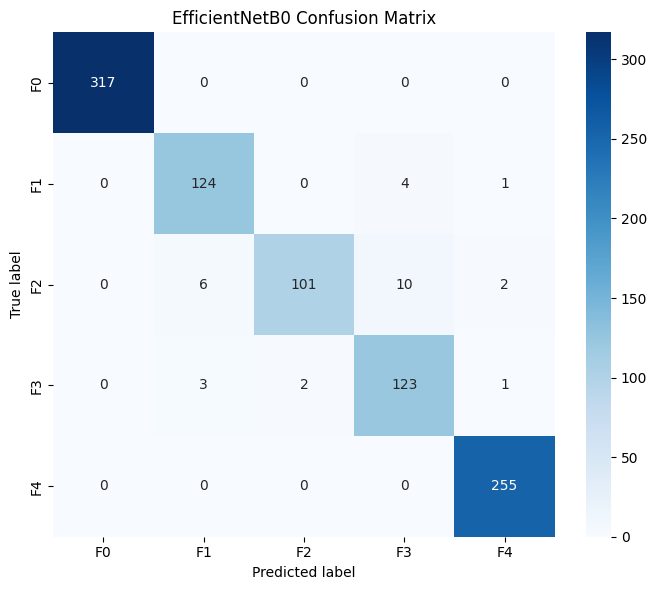

Inference time: 1.96 seconds
Test images: 949
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step

MobileNetV2 classification report
              precision    recall  f1-score   support

          F0     1.0000    1.0000    1.0000       317
          F1     0.9297    0.9225    0.9261       129
          F2     0.9167    0.8319    0.8722       119
          F3     0.8676    0.9147    0.8906       129
          F4     0.9808    1.0000    0.9903       255

    accuracy                         0.9568       949
   macro avg     0.9390    0.9338    0.9358       949
weighted avg     0.9568    0.9568    0.9564       949



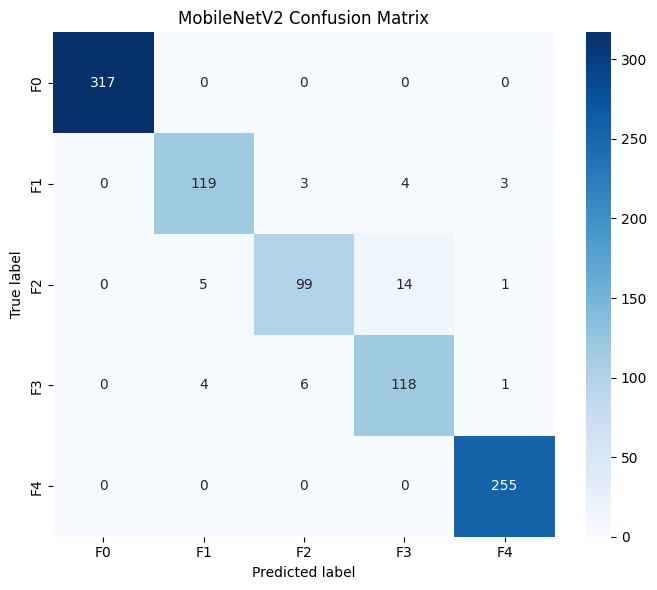

Inference time: 1.04 seconds
Test images: 949


,Model,Accuracy,Macro precision,Weighted precision,Macro recall,Weighted recall,Macro F1,Weighted F1,AUC macro OVR,AUC weighted OVR,Parameters,Inference seconds (test set),Test images,Inference ms/image
0,EfficientNetB0,0.9694,0.9591,0.9703,0.9527,0.9694,0.9547,0.9691,0.9962,0.9974,4378792,1.9615,949,2.0669
1,MobileNetV2,0.9568,0.9390,0.9568,0.9338,0.9568,0.9358,0.9564,0.9977,0.9985,2587205,1.0411,949,1.0970


In [19]:

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

def evaluate_model(model, model_name, test_images=x_test):

    # ==========================================
    # INFERENCE TIME
       # ==========================================
    start_inf = time.time()
    probabilities = model.predict(test_images)
    end_inf = time.time()

    inference_seconds = end_inf - start_inf

    # Predicted and true labels
    pred = np.argmax(probabilities, axis=1)
    true = y_test_int

    assert len(test_images) == len(true), (
        "Test images and labels do not match."
    )

    # ==========================================
    # EVALUATION METRICS
    # ==========================================
    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(true, pred),

        "Macro precision": precision_score(
            true, pred, average="macro", zero_division=0
        ),
        "Weighted precision": precision_score(
            true, pred, average="weighted", zero_division=0
        ),

        "Macro recall": recall_score(
            true, pred, average="macro", zero_division=0
        ),
        "Weighted recall": recall_score(
            true, pred, average="weighted", zero_division=0
        ),

        "Macro F1": f1_score(
            true, pred, average="macro", zero_division=0
        ),
        "Weighted F1": f1_score(
            true, pred, average="weighted", zero_division=0
        ),

        "AUC macro OVR": roc_auc_score(
            y_test, probabilities,
            multi_class="ovr", average="macro"
        ),
        "AUC weighted OVR": roc_auc_score(
            y_test, probabilities,
            multi_class="ovr", average="weighted"
        ),

        "Parameters": model.count_params(),
        "Inference seconds (test set)": inference_seconds,
        "Test images": len(test_images),
        "Inference ms/image": (
            1000 * inference_seconds / len(test_images)
        )
    }

    # ==========================================
    # CLASSIFICATION REPORT
    # ==========================================
    print(f"\n{model_name} classification report")

    print(classification_report(
        true,
        pred,
        labels=np.arange(NUM_CLASSES),
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    ))

    # ==========================================
    # CONFUSION MATRIX
    # ==========================================
    cm = confusion_matrix(
        true, pred, labels=np.arange(NUM_CLASSES)
    )

    plt.figure(figsize=(7, 6))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES
    )

    plt.title(f"{model_name} Confusion Matrix")
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.tight_layout()
    plt.show()

    print(f"Inference time: {inference_seconds:.2f} seconds")
    print(f"Test images: {len(test_images)}")

    return results, probabilities


# ==========================================
# EVALUATE BOTH MODELS
# ==========================================

results_eff, probs_eff = evaluate_model(
    efficientnet_model, "EfficientNetB0", x_test
)

results_mob, probs_mob = evaluate_model(
    mobilenet_model, "MobileNetV2", x_test
)


# ==========================================
# COMPARISON TABLE
# ==========================================

results_df = pd.DataFrame([
    results_eff,
    results_mob
])

display(results_df.round(4))


##Plot training curves

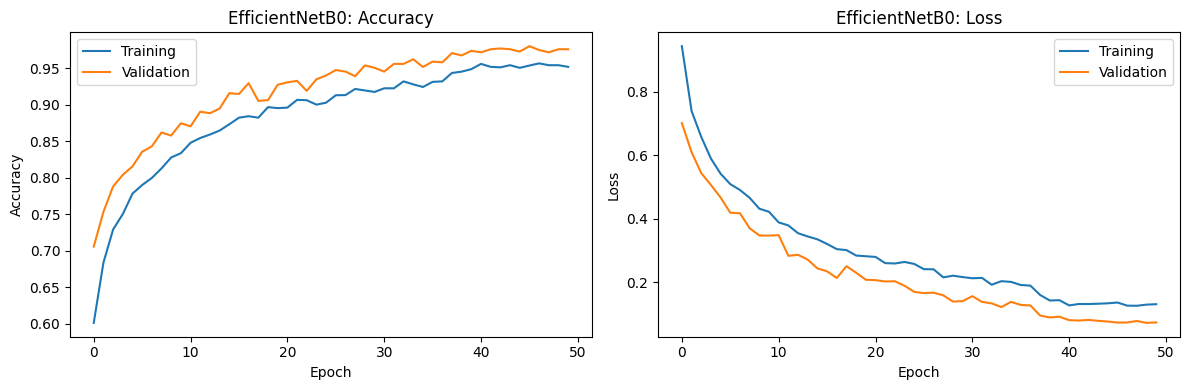

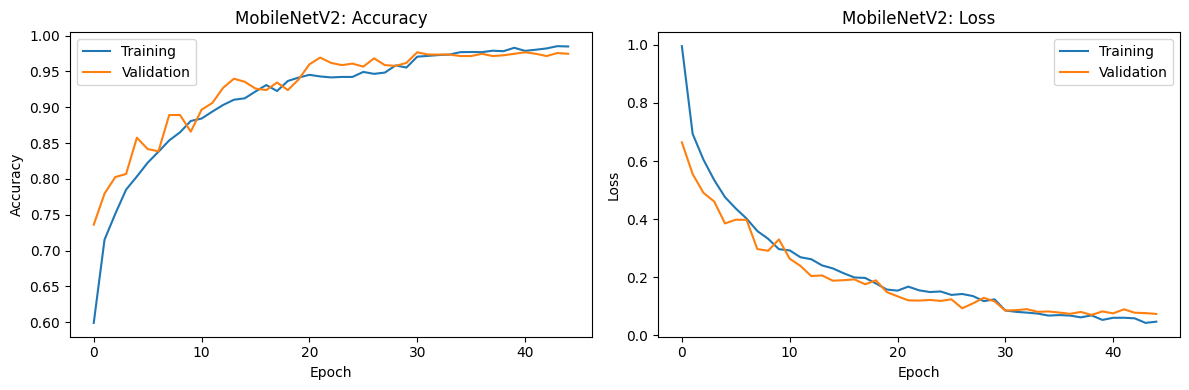

In [21]:
def plot_history(history, name):
    if history is None:
        return
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history.history.get("accuracy", []), label="Training")
    axes[0].plot(history.history.get("val_accuracy", []), label="Validation")
    axes[0].set_title(f"{name}: Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()

    axes[1].plot(history.history.get("loss", []), label="Training")
    axes[1].plot(history.history.get("val_loss", []), label="Validation")
    axes[1].set_title(f"{name}: Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

plot_history(history_eff, "EfficientNetB0")
plot_history(history_mob, "MobileNetV2")

## 14. Save models and results

In [ ]:
os.makedirs("/content/baseline_outputs", exist_ok=True)
efficientnet_model.save("/content/baseline_outputs/efficientnetb0_liver_fibrosis.keras")
mobilenet_model.save("/content/baseline_outputs/mobilenetv2_liver_fibrosis.keras")
results_df.to_csv("/content/baseline_outputs/baseline_test_results.csv", index=False)

# Save split indices so the exact split can be reused in later experiments.
np.savez(
    "/content/baseline_outputs/data_split_indices.npz",
    train=idx_train, validation=idx_val, test=idx_test
)

print("Saved models, results, and split indices under /content/baseline_outputs/")